# BaraLens: Understanding African Perspectives on Regional Integration Through Machine Learning

## 1. Dataset description

**Source:** Afrobarometer Round 10 merged dataset (38 countries, 2024/2025 fieldwork, release 25 Feb 2026).
- Data: https://www.afrobarometer.org/survey-resource/merged-round-10-data-38-countries-2025/
- Codebook: https://www.afrobarometer.org/survey-resource/merged-round-10-codebook-38-countries-2025/

Afrobarometer runs face-to-face, nationally representative surveys of adults (18+). The merged file has **50,961 respondents and 425 variables**.
I extracted the respondent ID plus the 26 survey columns used here (27 columns) from the SPSS `.sav` file into `data/afrobarometer_r10_baralens.csv`
(raw survey codes kept, so all cleaning is visible in this notebook).

## 2. Mission connection

Many young Africans only meet politics through social media and headlines. My mission is to learn how governance
and regional cooperation actually work. This project asks a narrower, measurable question:

> **How do demographic, educational and governance-related characteristics relate to people's openness to regional integration?**

The target is a **Regional Openness Index (0–1)**. The model does **not** measure leadership potential or the effect of civic education;
it only describes patterns in survey answers.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

raw = pd.read_csv("data/afrobarometer_r10_baralens.csv")
print(raw.shape)

(50961, 27)


## 3. Data inspection

In [2]:
raw.head()

,RESPNO,COUNTRY,COUNTRY.BY.REGION,URBRUR,Q1,Q7A,Q22,Q65A,Q65D,Q67F,...,Q74,Q75,Q76A,Q76B,Q88D,Q88F,Q94A,Q96,Q101,withinwt_hh
0,ANG0001,2.0,3.0,2.0,21.0,4.0,9.0,0.0,0.0,9.0,...,0.0,3.0,2.0,2.0,3.0,3.0,1.0,2.0,2.0,0.742673
1,ANG0002,2.0,3.0,2.0,40.0,2.0,3.0,4.0,0.0,5.0,...,0.0,3.0,2.0,2.0,4.0,4.0,1.0,4.0,1.0,0.618894
2,ANG0003,2.0,3.0,2.0,25.0,3.0,9.0,0.0,0.0,9.0,...,0.0,9.0,9.0,9.0,5.0,1.0,0.0,5.0,1.0,0.742673
3,ANG0004,2.0,3.0,1.0,20.0,2.0,9.0,3.0,4.0,2.0,...,0.0,1.0,2.0,2.0,4.0,4.0,2.0,2.0,1.0,0.793267
4,ANG0005,2.0,3.0,1.0,18.0,2.0,2.0,3.0,4.0,9.0,...,0.0,2.0,2.0,2.0,4.0,2.0,1.0,4.0,1.0,0.495792


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 50961 entries, 0 to 50960
Data columns (total 27 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   RESPNO             50961 non-null  str    
 1   COUNTRY            50961 non-null  float64
 2   COUNTRY.BY.REGION  50961 non-null  float64
 3   URBRUR             50961 non-null  float64
 4   Q1                 50961 non-null  float64
 5   Q7A                50961 non-null  float64
 6   Q22                50961 non-null  float64
 7   Q65A               50961 non-null  float64
 8   Q65D               50961 non-null  float64
 9   Q67F               50961 non-null  float64
 10  Q70A               50961 non-null  float64
 11  Q70B               50961 non-null  float64
 12  Q71A               50961 non-null  float64
 13  Q73A               50961 non-null  float64
 14  Q73B               50961 non-null  float64
 15  Q73C               50961 non-null  float64
 16  Q73D               50961 non-null

In [4]:
raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
COUNTRY,50961.0,30.45,15.19,2.00,21.00,31.00,43.00,54.00
COUNTRY.BY.REGION,50961.0,2.31,1.27,1.00,1.00,2.00,3.00,5.00
URBRUR,50961.0,1.52,0.53,1.00,1.00,2.00,2.00,3.00
Q1,50961.0,38.66,22.40,18.00,26.00,35.00,48.00,999.00
Q7A,50961.0,1.22,1.28,0.00,0.00,1.00,2.00,9.00
Q22,50961.0,2.70,1.32,-1.00,2.00,3.00,3.00,9.00
Q65A,50961.0,2.44,1.61,0.00,1.00,3.00,4.00,9.00
Q65D,50961.0,2.00,1.88,0.00,0.00,2.00,4.00,9.00
Q67F,50961.0,5.13,2.50,1.00,4.00,4.00,9.00,9.00
Q70A,50961.0,239.92,1514.74,1.00,4.00,4.00,5.00,9994.00


Every survey answer is stored as a number code. Some codes are real answers, others mean
*refused* (8 / 98), *don't know* (9 / 99), *not applicable* (5, 7) or *not asked* (-1, 9994).
If I leave those codes in, the model would treat "don't know = 9" as a very high answer, so they must be turned into missing values first.

## 4. Missing-value analysis

In [5]:
# Which codes are real answers for each question (everything else = missing)
valid_ranges = {
    "Q1": (18, 100), "Q96": (0, 9), "Q73D": (1, 4), "Q70B": (1, 5), "Q65D": (0, 4),
    "Q94A": (0, 3), "Q74": (0, 1), "Q73A": (0, 4), "Q73B": (0, 3), "Q73C": (0, 3),
    "Q88D": (1, 5), "Q88F": (1, 5),
}

def clean_survey_data(df):
    df = df.copy()
    for col, (low, high) in valid_ranges.items():
        df[col] = df[col].where(df[col].between(low, high))
    # Q76A / Q76B: 2 = agree with statement 1, 3 = agree with statement 2. 5, 8, 9 are not usable
    for col in ["Q76A", "Q76B"]:
        df[col] = df[col].where(df[col].isin([2, 3]))
    return df

clean = clean_survey_data(raw)

missing = pd.DataFrame({
    "missing_before_cleaning": raw.isna().sum(),
    "missing_after_cleaning": clean.isna().sum(),
})
missing["pct_after"] = (missing["missing_after_cleaning"] / len(clean) * 100).round(1)
missing.sort_values("pct_after", ascending=False)

,missing_before_cleaning,missing_after_cleaning,pct_after
Q70B,0,10662,20.9
Q73D,0,6980,13.7
Q76B,0,1935,3.8
Q76A,0,1638,3.2
Q73B,0,1108,2.2
Q73A,0,1110,2.2
Q74,0,1093,2.1
Q73C,0,1082,2.1
Q88F,0,649,1.3
Q88D,0,419,0.8


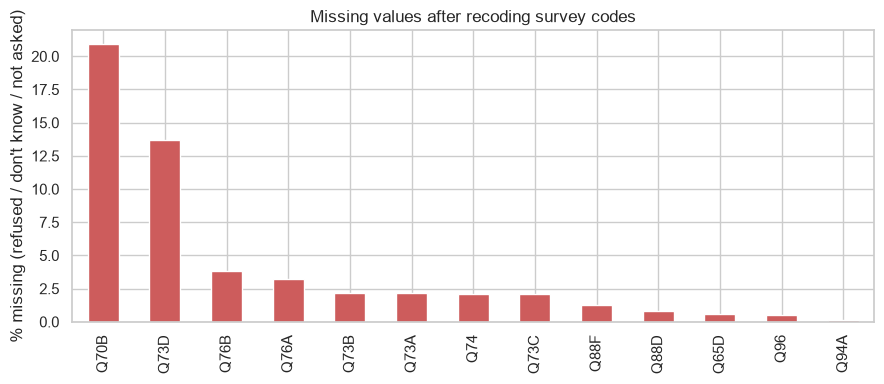

In [6]:
pct = missing["pct_after"].sort_values(ascending=False)
pct = pct[pct > 0]
plt.figure(figsize=(9, 4))
pct.plot(kind="bar", color="indianred")
plt.ylabel("% missing (refused / don't know / not asked)")
plt.title("Missing values after recoding survey codes")
plt.tight_layout()
plt.show()

The biggest gaps are in `Q70B` (African Union recognises our needs, ~21%) and `Q73D` (border ease, ~14%), mostly
"don't know / haven't heard enough". Those people genuinely have no opinion, so I don't invent one by imputing:
rows with any missing model input are dropped later. We still keep more than 35,000 rows.

## 5. Feature engineering – building the target

The questionnaire items `Q73D, Q74, Q75, Q76A, Q76B` were my starting point, but they don't measure one thing:
`Q73D` is a *perception* (how easy is it to cross borders), `Q74` is *awareness* (heard of AfCFTA, yes/no) and `Q75` is a
nominal choice. Only `Q76A/B` are attitudes. So I built a broader **Regional Openness Index** from 7 attitude items,
each rescaled to 0–1 so that 1 = most open:

| Item | Question | Recoding |
|---|---|---|
| Q73A | Migrants are good/bad for the economy | 0–4 → /4 |
| Q73B | Admit more/fewer job seekers from other countries | 0–3 → /3 |
| Q73C | Admit more/fewer refugees | 0–3 → /3 |
| Q76A | Open trade vs protect local producers | open = 1, protect = 0 |
| Q76B | Free movement in the region vs limit movement | free = 1, limit = 0 |
| Q88D | Like/dislike immigrants as neighbours | 1–5 → (x-1)/4 |
| Q88F | Like/dislike refugees as neighbours | 1–5 → (x-1)/4 |

The index is the mean of the items a person answered (needs at least 5 of 7).

In [7]:
def build_integration_index(df):
    items = pd.DataFrame({
        "Q73A": df["Q73A"] / 4,
        "Q73B": df["Q73B"] / 3,
        "Q73C": df["Q73C"] / 3,
        "Q76A": df["Q76A"].map({2: 1.0, 3: 0.0}),
        "Q76B": df["Q76B"].map({2: 1.0, 3: 0.0}),
        "Q88D": (df["Q88D"] - 1) / 4,
        "Q88F": (df["Q88F"] - 1) / 4,
    })
    answered = items.notna().sum(axis=1)
    index = items.mean(axis=1).where(answered >= 5)
    return index, items

clean["openness_index"], index_items = build_integration_index(clean)

def cronbach_alpha(items):
    items = items.dropna()
    k = items.shape[1]
    return k / (k - 1) * (1 - items.var(ddof=1).sum() / items.sum(axis=1).var(ddof=1))

print("Cronbach's alpha (7 items):", round(cronbach_alpha(index_items), 3))
print(index_items.corr().round(2))

Cronbach's alpha (7 items): 0.533
      Q73A  Q73B  Q73C  Q76A  Q76B  Q88D  Q88F
Q73A  1.00  0.28  0.13  0.08  0.09  0.18  0.12
Q73B  0.28  1.00  0.39  0.03  0.04  0.12  0.10
Q73C  0.13  0.39  1.00  0.05  0.07  0.12  0.21
Q76A  0.08  0.03  0.05  1.00  0.42  0.05  0.07
Q76B  0.09  0.04  0.07  0.42  1.00  0.06  0.07
Q88D  0.18  0.12  0.12  0.05  0.06  1.00  0.52
Q88F  0.12  0.10  0.21  0.07  0.07  0.52  1.00


**Honest note on the index:** Cronbach's alpha is about 0.53, below the usual 0.6–0.7 for a single scale. The correlation table shows
three groups of items (views on migrants, trade/free-movement policy, migrants as neighbours). So I treat this as a
**formative index** – it combines the three parts of the AU / AfCFTA integration agenda (people, trade, movement) –
and not as a measure of one hidden trait. With ~220 distinct values it works as a continuous target.

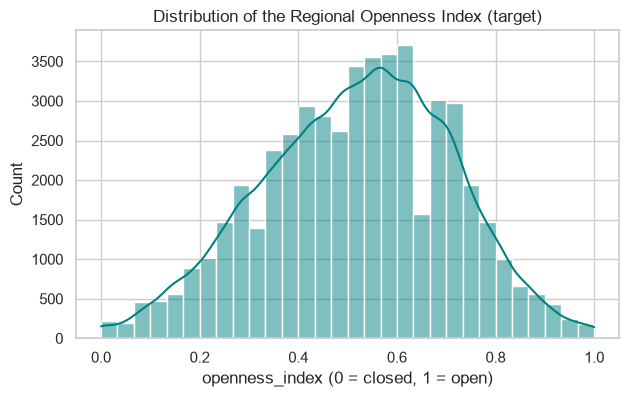

In [8]:
plt.figure(figsize=(7, 4))
sns.histplot(clean["openness_index"].dropna(), bins=30, kde=True, color="teal")
plt.title("Distribution of the Regional Openness Index (target)")
plt.xlabel("openness_index (0 = closed, 1 = open)")
plt.show()

## 6. Feature selection

I picked 10 predictors that are about **demographics, education and governance**, which is the scope of the mission:

| Feature | Source | Type |
|---|---|---|
| age | Q1 | numeric |
| education | Q96 (0 = none … 9 = post-graduate) | numeric (ordinal) |
| border_ease | Q73D (1 = very difficult … 4 = very easy) | numeric (ordinal) |
| au_recognition | Q70B AU recognises our needs (1–5) | numeric (ordinal) |
| social_media_news | Q65D (0 = never … 4 = every day) | numeric (ordinal) |
| gender | Q101 | categorical |
| area | URBRUR | categorical |
| country | COUNTRY (38 countries) | categorical |
| employment | Q94A | categorical |
| afcfta_aware | Q74 heard of AfCFTA | categorical |

Not used: items that are *part of the target* (Q73A–C, Q76A/B, Q88D/F – using them would leak the answer),
IDs (RESPNO), weights, and `Q75` (it is itself a trade-openness answer, too close to the target).

Which features matter most is checked after training (section 13): country has by far the largest effect, then AU recognition, AfCFTA awareness and border ease.


In [9]:
country_names = {
    2: "Angola", 3: "Benin", 4: "Botswana", 7: "Cabo Verde", 8: "Cameroon", 10: "Chad", 11: "Comoros",
    13: "Congo-Brazzaville", 14: "Cote d'Ivoire", 19: "Eswatini", 21: "Gabon", 22: "Gambia", 23: "Ghana",
    24: "Guinea", 25: "Guinea-Bissau", 26: "Kenya", 27: "Lesotho", 28: "Liberia", 30: "Madagascar",
    31: "Malawi", 32: "Mali", 33: "Mauritania", 34: "Mauritius", 35: "Morocco", 36: "Mozambique",
    37: "Namibia", 39: "Nigeria", 41: "Sao Tome and Principe", 42: "Senegal", 43: "Seychelles",
    44: "Sierra Leone", 46: "South Africa", 49: "Tanzania", 50: "Togo", 51: "Tunisia", 52: "Uganda",
    53: "Zambia", 54: "Zimbabwe",
}

def make_model_table(df):
    table = pd.DataFrame({
        "age": df["Q1"],
        "education": df["Q96"],
        "border_ease": df["Q73D"],
        "au_recognition": df["Q70B"],
        "social_media_news": df["Q65D"],
        "gender": df["Q101"].map({1: "Man", 2: "Woman"}),
        "area": df["URBRUR"].map({1: "Urban", 2: "Rural", 3: "Peri-Urban"}),
        "country": df["COUNTRY"].map(country_names),
        "employment": df["Q94A"].map({0: "Not working, not looking", 1: "Not working, looking",
                                      2: "Part time", 3: "Full time"}),
        "afcfta_aware": df["Q74"].map({0: "No", 1: "Yes"}),
        "openness_index": df["openness_index"],
    })
    return table.dropna()

data = make_model_table(clean)

# Put 500 respondents aside as "new survey data". They are never used for training or testing here;
# later they are uploaded to the API's /retrain endpoint to show how the model is updated with new data.
new_survey_rows = data.sample(500, random_state=RANDOM_STATE)
data = data.drop(new_survey_rows.index)

NUMERIC_FEATURES = ["age", "education", "border_ease", "au_recognition", "social_media_news"]
CATEGORICAL_FEATURES = ["gender", "area", "country", "employment", "afcfta_aware"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
TARGET = "openness_index"

print("Rows used for modelling:", len(data), "| kept aside as new data:", len(new_survey_rows), "| predictors:", len(FEATURES))
data.head()

Rows used for modelling: 35488 | kept aside as new data: 500 | predictors: 10


,age,education,border_ease,au_recognition,social_media_news,gender,area,country,employment,afcfta_aware,openness_index
1,40.0,4.0,4.0,4.0,0.0,Man,Rural,Angola,"Not working, looking",No,0.630952
3,20.0,2.0,2.0,1.0,4.0,Man,Urban,Angola,Part time,No,0.595238
4,18.0,4.0,1.0,4.0,4.0,Man,Urban,Angola,"Not working, looking",No,0.678571
8,56.0,4.0,1.0,4.0,3.0,Woman,Urban,Angola,"Not working, not looking",No,0.333333
9,48.0,4.0,2.0,3.0,2.0,Woman,Urban,Angola,Full time,Yes,0.333333


## 7. Visualisations

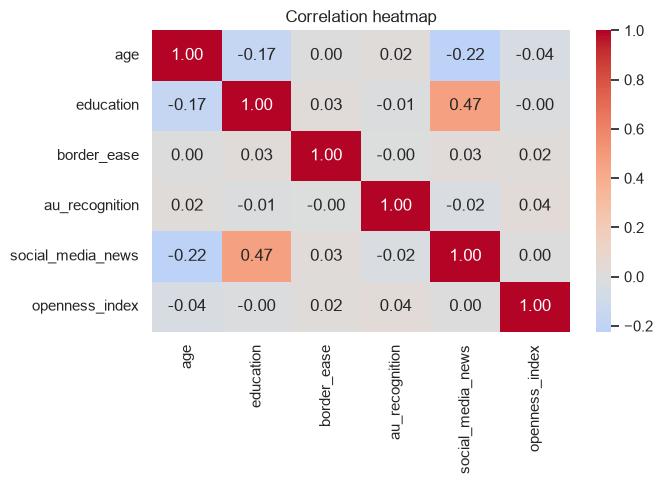

In [10]:
# Correlation heatmap (numeric features + target)
plt.figure(figsize=(7, 5))
sns.heatmap(data[NUMERIC_FEATURES + [TARGET]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.tight_layout()
plt.show()

The numeric features each have only weak linear correlation with the index (all small in size). This already tells me a
linear model will not explain much of the variance – attitudes depend on many things not in a survey.

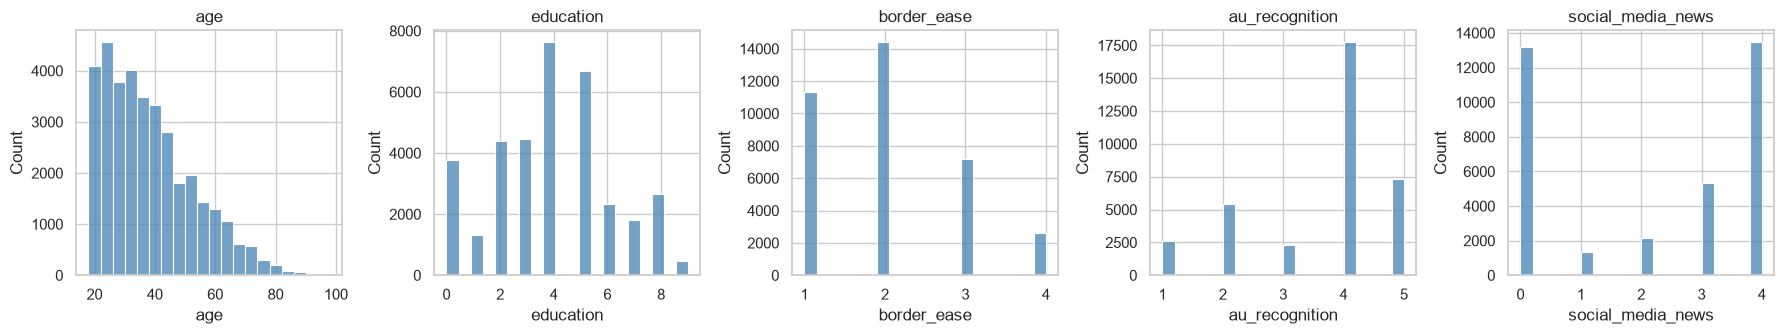

In [11]:
# Distributions of numeric features
fig, axes = plt.subplots(1, 5, figsize=(18, 3.5))
for ax, col in zip(axes, NUMERIC_FEATURES):
    sns.histplot(data[col], ax=ax, bins=20, color="steelblue")
    ax.set_title(col)
plt.tight_layout()
plt.show()

Age is right-skewed (most people are 18–45), and the other numeric inputs are short answer scales with uneven counts (most people answer 4 = agree on AU recognition, and social media news is split between never and every day). Because the ranges are so different (age up to 100, the others 0–9), I **standardise** the numeric features before training. Their order is meaningful, so I keep them as numbers instead of one-hot encoding them.

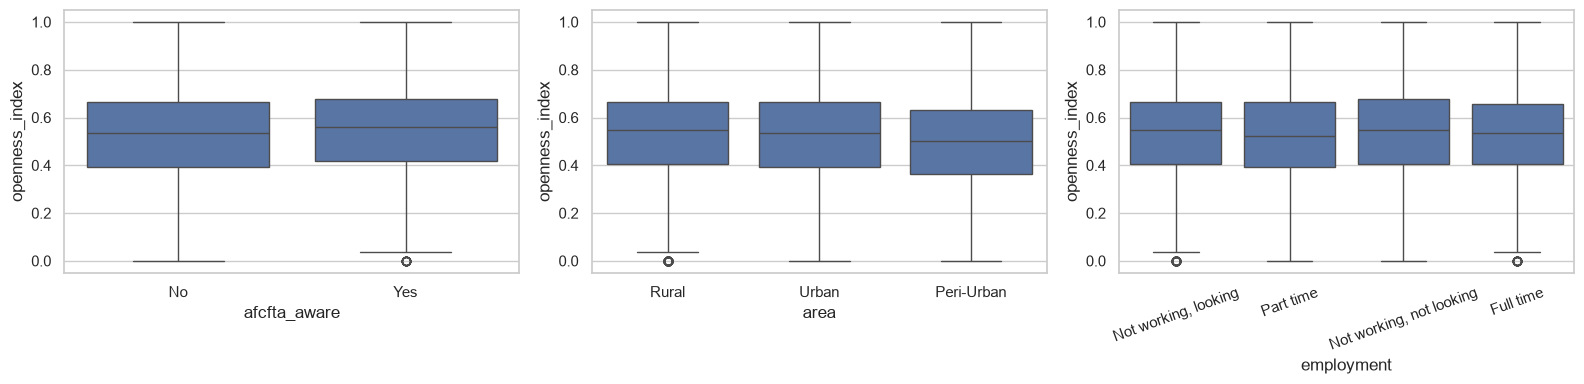

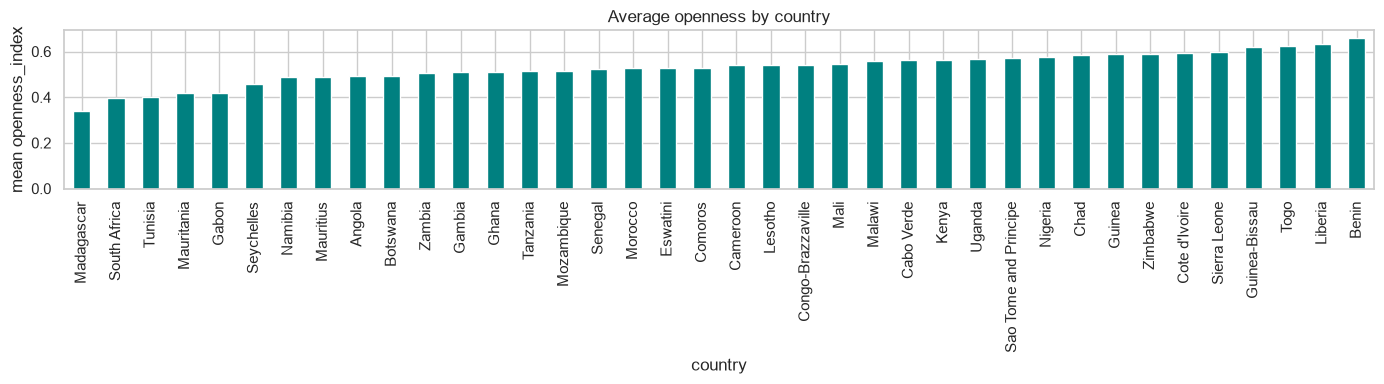

In [12]:
# Boxplots: does the index differ across categories?
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.boxplot(data=data, x="afcfta_aware", y=TARGET, ax=axes[0])
sns.boxplot(data=data, x="area", y=TARGET, ax=axes[1])
sns.boxplot(data=data, x="employment", y=TARGET, ax=axes[2])
axes[2].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

# Country has the biggest spread, so show mean index per country
plt.figure(figsize=(14, 4))
data.groupby("country")[TARGET].mean().sort_values().plot(kind="bar", color="teal")
plt.ylabel("mean openness_index")
plt.title("Average openness by country")
plt.tight_layout()
plt.show()

The boxplots show only small differences: people who have heard of AfCFTA are slightly more open, peri-urban residents slightly less, and employment barely matters. Country is different: the average ranges from about 0.34 in Madagascar to about 0.66 in Benin. So I keep **country as a one-hot feature** (it carries most of the signal) and keep the other categoricals for their small extra effects.

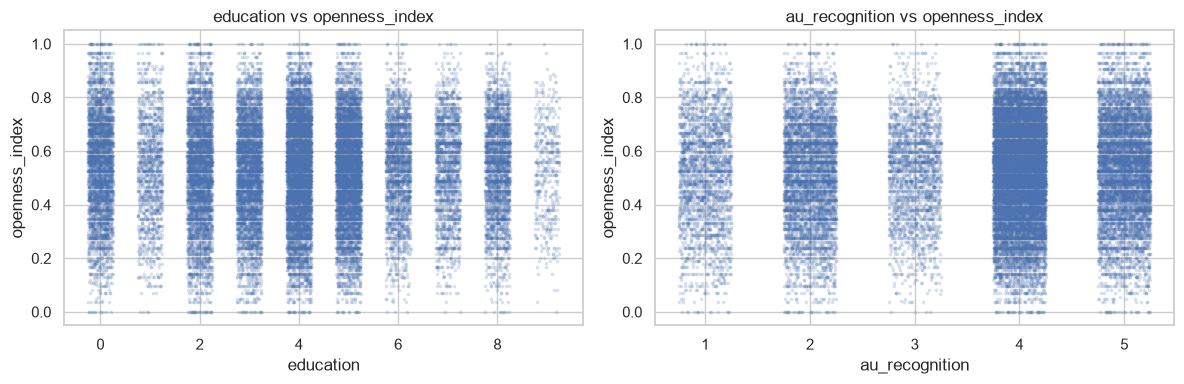

In [13]:
# Scatter of two features against the target (jitter because answers are whole numbers)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ["education", "au_recognition"]):
    jitter = np.random.default_rng(RANDOM_STATE).uniform(-0.25, 0.25, len(data))
    ax.scatter(data[col] + jitter, data[TARGET], s=3, alpha=0.15)
    ax.set_xlabel(col)
    ax.set_ylabel(TARGET)
    ax.set_title(f"{col} vs openness_index")
plt.tight_layout()
plt.show()

Within each education level or AU-recognition answer, the index covers almost the whole 0–1 range and the centre moves only a little. This confirms the heatmap: each feature alone is weakly related to the target, so I don't expect a high R², and I judge every model against a simple baseline (always predict the training mean).

## 8. Train / test split

One fixed 80/20 split (`random_state=42`) is used for **all** models so the comparison is fair.

In [14]:
X = data[FEATURES]
y = data[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("train:", X_train.shape, "test:", X_test.shape)

# Simplest possible "model": always predict the training mean. Every real model should beat this.
baseline_mse = mean_squared_error(y_test, np.full(len(y_test), y_train.mean()))
print("Baseline test MSE (predict the training mean):", round(baseline_mse, 5))

train: (28390, 10) test: (7098, 10)
Baseline test MSE (predict the training mean): 0.03569


## 9. Categorical encoding + standardisation (no data leakage)

- Numeric features → `StandardScaler`
- Categorical features → `OneHotEncoder(handle_unknown="ignore")`

Both live inside a `Pipeline`, so `.fit()` only ever sees the **training** rows. The test set is transformed with the
means/stds/categories learned from training data. The same pipeline is saved with the model, so the API does the exact same preprocessing.

In [15]:
def make_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), NUMERIC_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES),
    ])

def make_pipeline(model):
    return Pipeline([("preprocess", make_preprocessor()), ("model", model)])

# quick look at the encoded training matrix
encoded = make_preprocessor().fit(X_train)
print("Columns after encoding:", len(encoded.get_feature_names_out()))

Columns after encoding: 54


## 10. Before training: scatter of the data

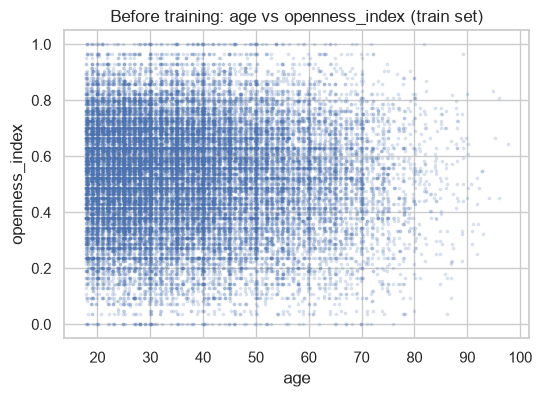

In [16]:
# "Before" view: the raw relationship between the strongest numeric feature and the target, no model yet
best_num = data[NUMERIC_FEATURES + [TARGET]].corr()[TARGET].drop(TARGET).abs().idxmax()
plt.figure(figsize=(6, 4))
jitter = np.random.default_rng(1).uniform(-0.25, 0.25, len(X_train))
plt.scatter(X_train[best_num] + jitter, y_train, s=3, alpha=0.15)
plt.xlabel(best_num)
plt.ylabel(TARGET)
plt.title(f"Before training: {best_num} vs openness_index (train set)")
plt.show()

`age` is picked automatically as the numeric feature most correlated with the index, but the cloud is almost flat: every age has people across the whole 0–1 range. One feature on its own can't predict openness, which is why the models use all 10 features together.

## 11. Models

Four models on the same split:
1. `LinearRegression` (closed-form least squares)
2. `SGDRegressor` (linear model trained with gradient descent)
3. `DecisionTreeRegressor`
4. `RandomForestRegressor`

### 11a. SGDRegressor hyperparameter experiments

I tune the learning rate `eta0` and the L2 penalty `alpha` with **5-fold cross-validation on the training set only**,
so the test set stays unseen until the final comparison.

In [17]:
sgd_search = GridSearchCV(
    make_pipeline(SGDRegressor(learning_rate="invscaling", penalty="l2", max_iter=1000, tol=1e-4,
                               random_state=RANDOM_STATE)),
    {"model__eta0": [0.0001, 0.001, 0.01, 0.1], "model__alpha": [0.0001, 0.001, 0.01]},
    scoring="neg_mean_squared_error", cv=5, n_jobs=-1,
)
sgd_search.fit(X_train, y_train)

sgd_table = pd.DataFrame({
    "eta0": sgd_search.cv_results_["param_model__eta0"],
    "alpha": sgd_search.cv_results_["param_model__alpha"],
    "cv_mse": -sgd_search.cv_results_["mean_test_score"],
}).sort_values("cv_mse")
sgd_table.round(5)

,eta0,alpha,cv_mse
2,0.0100,0.0001,0.03050
6,0.0100,0.0010,0.03051
3,0.1000,0.0001,0.03087
7,0.1000,0.0010,0.03088
10,0.0100,0.0100,0.03093
11,0.1000,0.0100,0.03127
1,0.0010,0.0001,0.03243
5,0.0010,0.0010,0.03245
9,0.0010,0.0100,0.03271
0,0.0001,0.0001,0.03708


In [18]:
best_sgd_params = {"eta0": sgd_search.best_params_["model__eta0"], "alpha": sgd_search.best_params_["model__alpha"]}
print("Best SGD settings (chosen by CV on training data):", best_sgd_params)

Best SGD settings (chosen by CV on training data): {'eta0': 0.01, 'alpha': 0.0001}


### 11b. SGD loss curves (train vs test MSE per epoch)

To see the loss per epoch I train SGD one pass at a time with `partial_fit`. The preprocessing is fitted on the
training data once, then reused for the test data.

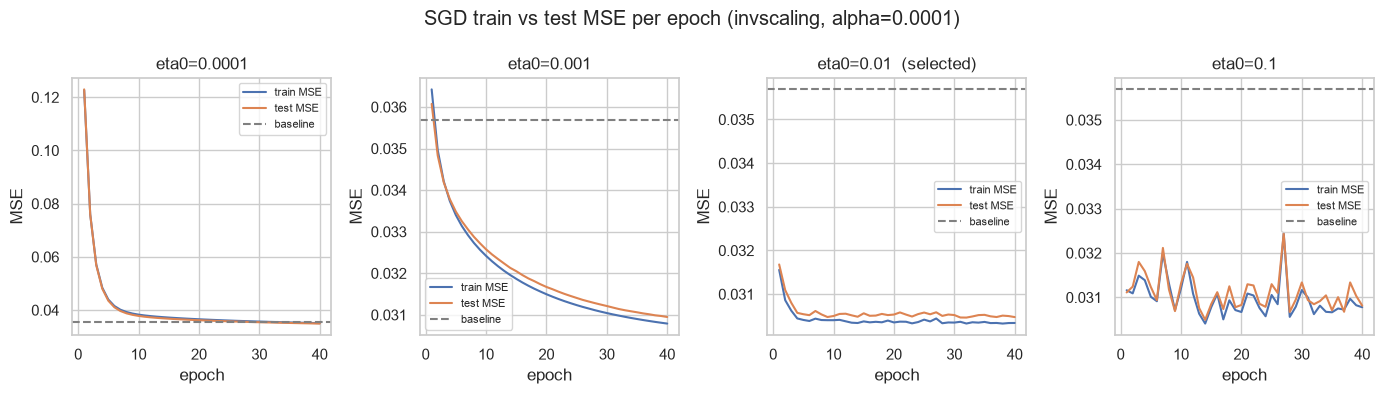

,eta0,train_mse_epoch40,test_mse_epoch40
0,0.0001,0.03509,0.03493
1,0.0010,0.03079,0.03095
2,0.0100,0.03034,0.03047
3,0.1000,0.03078,0.03081


In [19]:
prep = make_preprocessor().fit(X_train)
X_train_enc = prep.transform(X_train)
X_test_enc = prep.transform(X_test)

def sgd_loss_curve(eta0, alpha, epochs=40):
    # same learning-rate schedule (invscaling) as the tuned SGD model
    sgd = SGDRegressor(learning_rate="invscaling", eta0=eta0, alpha=alpha, random_state=RANDOM_STATE)
    rng = np.random.default_rng(RANDOM_STATE)
    train_curve, test_curve = [], []
    for epoch in range(epochs):
        order = rng.permutation(X_train_enc.shape[0])  # shuffle each epoch like normal SGD
        sgd.partial_fit(X_train_enc[order], y_train.values[order])
        train_curve.append(mean_squared_error(y_train, sgd.predict(X_train_enc)))
        test_curve.append(mean_squared_error(y_test, sgd.predict(X_test_enc)))
    return train_curve, test_curve

plt.figure(figsize=(14, 4))
final_losses = []
for i, eta0 in enumerate([0.0001, 0.001, 0.01, 0.1]):
    train_curve, test_curve = sgd_loss_curve(eta0, best_sgd_params["alpha"])
    final_losses.append({"eta0": eta0, "train_mse_epoch40": train_curve[-1], "test_mse_epoch40": test_curve[-1]})
    plt.subplot(1, 4, i + 1)
    plt.plot(range(1, 41), train_curve, label="train MSE")
    plt.plot(range(1, 41), test_curve, label="test MSE")
    plt.axhline(baseline_mse, color="grey", linestyle="--", label="baseline")
    title = f"eta0={eta0}" + ("  (selected)" if eta0 == best_sgd_params["eta0"] else "")
    plt.title(title)
    plt.xlabel("epoch")
    plt.ylabel("MSE")
    plt.legend(fontsize=8)
plt.suptitle(f"SGD train vs test MSE per epoch (invscaling, alpha={best_sgd_params['alpha']})")
plt.tight_layout()
plt.show()
pd.DataFrame(final_losses).round(5)

**What the experiments show (numbers from the tables above):**

- Cross-validation picked `eta0=0.01, alpha=0.0001` (CV MSE 0.0305). `alpha` matters little: for eta0=0.01 the CV MSE only moves from 0.0305 to 0.0309 across the three alphas.
- The learning rate matters a lot. With `eta0=0.0001` the test loss is still 0.0349 after 40 epochs – barely better than the mean baseline (0.0357) – because the steps are too small. `eta0=0.001` gets to 0.0310, and the selected `eta0=0.01` reaches the lowest test MSE (0.0305). `eta0=0.1` ends a little higher (0.0308) and its curve is less smooth because the steps are bigger.
- Train and test curves stay very close together, so the linear model is **not overfitting**. Its limit is underfitting: there is only a weak linear signal in these features.

In [20]:
# Number of epochs: train the selected settings for 80 epochs and read the loss at different stopping points
train_curve, test_curve = sgd_loss_curve(best_sgd_params["eta0"], best_sgd_params["alpha"], epochs=80)
epoch_table = pd.DataFrame({"epochs": [1, 5, 10, 20, 40, 80]})
epoch_table["train_mse"] = [train_curve[e - 1] for e in epoch_table["epochs"]]
epoch_table["test_mse"] = [test_curve[e - 1] for e in epoch_table["epochs"]]
epoch_table.round(5)


,epochs,train_mse,test_mse
0,1,0.03156,0.03168
1,5,0.03041,0.03054
2,10,0.03040,0.03050
3,20,0.03035,0.03053
4,40,0.03034,0.03047
5,80,0.03035,0.03049


Most of the improvement happens in the first 5 epochs (test MSE 0.0317 → 0.0305). From about 10 epochs the test loss stays at about 0.0305, and 80 epochs is no better and doesn't start overfitting either. So the final SGD model uses `max_iter=1000` with `tol=1e-4`, which stops by itself once the loss stops improving.

### 11c. Train all four models

In [21]:
# Decision tree: pick max_depth with 5-fold CV on the TRAINING set only (the test set is not used for tuning)
tree_search = GridSearchCV(
    make_pipeline(DecisionTreeRegressor(random_state=RANDOM_STATE)),
    {"model__max_depth": [4, 6, 8, 10, 12], "model__min_samples_leaf": [20, 50]},
    scoring="neg_mean_squared_error", cv=5, n_jobs=-1,
)
tree_search.fit(X_train, y_train)
print("Decision tree best params:", tree_search.best_params_)

models = {
    "LinearRegression": make_pipeline(LinearRegression()),
    "SGDRegressor": make_pipeline(SGDRegressor(learning_rate="invscaling", eta0=best_sgd_params["eta0"],
                                               alpha=best_sgd_params["alpha"], max_iter=1000, tol=1e-4,
                                               random_state=RANDOM_STATE)),
    "DecisionTree": tree_search.best_estimator_,
    "RandomForest": make_pipeline(RandomForestRegressor(n_estimators=150, max_depth=14, min_samples_leaf=10,
                                                        n_jobs=-1, random_state=RANDOM_STATE)),
}

results = []
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    train_pred = pipe.predict(X_train)
    test_pred = pipe.predict(X_test)
    results.append({
        "model": name,
        "train_mse": mean_squared_error(y_train, train_pred),
        "test_mse": mean_squared_error(y_test, test_pred),
        "test_r2": r2_score(y_test, test_pred),
    })

results = pd.DataFrame(results).sort_values("test_mse").reset_index(drop=True)
print("Baseline (always predict the training mean) test MSE:", round(baseline_mse, 5))
results.round(5)

Decision tree best params: {'model__max_depth': 12, 'model__min_samples_leaf': 50}


Baseline (always predict the training mean) test MSE: 0.03569


,model,train_mse,test_mse,test_r2
0,LinearRegression,0.03032,0.03048,0.14594
1,SGDRegressor,0.03039,0.03056,0.14362
2,RandomForest,0.02905,0.03076,0.13816
3,DecisionTree,0.03074,0.03121,0.12552


**Best model: LinearRegression**, because it has the lowest test MSE (0.03048) on the shared test set. SGDRegressor is right behind it (0.03056); RandomForest (0.03076) and DecisionTree (0.03121) are worse on unseen data. The full justification is in section 14.

## 12. Train / test MSE comparison

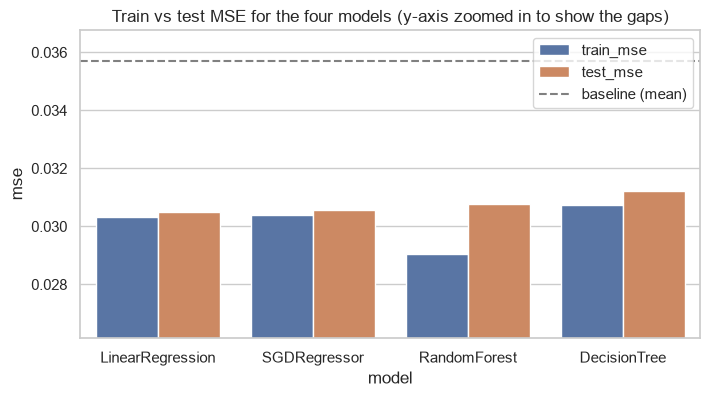

In [22]:
plot_df = results.melt(id_vars="model", value_vars=["train_mse", "test_mse"], var_name="split", value_name="mse")
plt.figure(figsize=(8, 4))
sns.barplot(data=plot_df, x="model", y="mse", hue="split")
plt.axhline(baseline_mse, color="grey", linestyle="--", label="baseline (mean)")
plt.ylim(plot_df["mse"].min() * 0.9, baseline_mse * 1.03)
plt.title("Train vs test MSE for the four models (y-axis zoomed in to show the gaps)")
plt.legend()
plt.show()

All four models beat the baseline (dashed line) but sit close together, between 0.0305 and 0.0312. The two linear models have almost the same train and test MSE (no overfitting), while RandomForest has a much lower train than test MSE, so it memorises the training data a little. With a weak, mostly additive signal, the simple linear model generalises best.

## 13. After training: fitted linear regression line

One-feature line: openness_index = 0.549 + -0.0005 x age


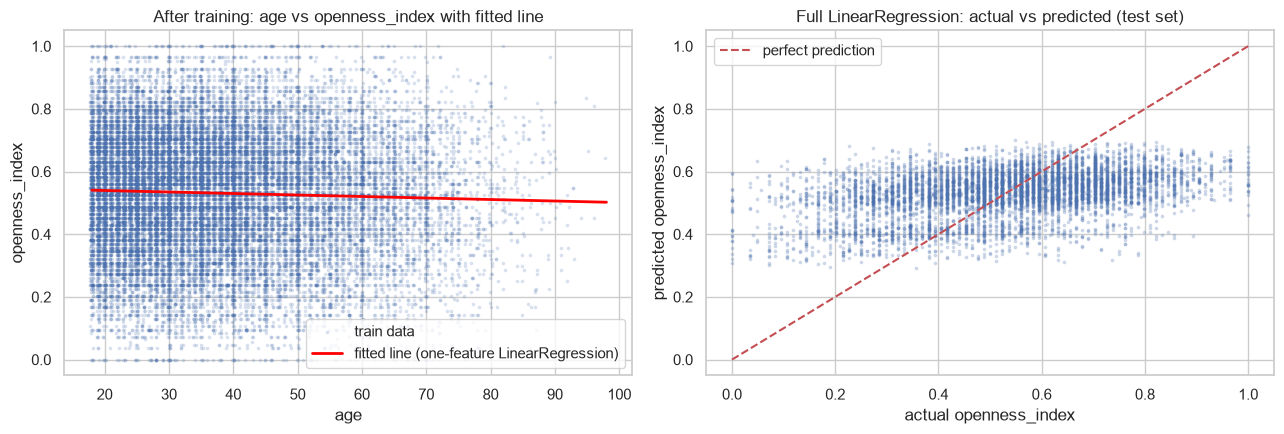

In [23]:
lin = models["LinearRegression"]
lin_test_pred = lin.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Same scatter as the "before" plot, with a fitted line from a ONE-feature linear regression.
# This small model is only for drawing the line; the real model uses all 10 features.
one_feature_lr = LinearRegression().fit(X_train[[best_num]], y_train)
axes[0].scatter(X_train[best_num] + np.random.default_rng(1).uniform(-0.25, 0.25, len(X_train)), y_train,
                s=3, alpha=0.15, label="train data")
xs = np.linspace(X_train[best_num].min(), X_train[best_num].max(), 50)
axes[0].plot(xs, one_feature_lr.predict(pd.DataFrame({best_num: xs})), color="red", linewidth=2,
             label="fitted line (one-feature LinearRegression)")
axes[0].set_xlabel(best_num)
axes[0].set_ylabel(TARGET)
axes[0].set_title(f"After training: {best_num} vs openness_index with fitted line")
axes[0].legend()
print(f"One-feature line: openness_index = {one_feature_lr.intercept_:.3f} + {one_feature_lr.coef_[0]:.4f} x {best_num}")

# Actual vs predicted for the full 10-feature LinearRegression
axes[1].scatter(y_test, lin_test_pred, s=3, alpha=0.2)
line = np.linspace(0, 1, 10)
axes[1].plot(line, line, "r--", label="perfect prediction")
axes[1].set_xlabel("actual openness_index")
axes[1].set_ylabel("predicted openness_index")
axes[1].set_title("Full LinearRegression: actual vs predicted (test set)")
axes[1].legend()
plt.tight_layout()
plt.show()


Left: the red line is a one-feature linear regression of the index on age, fitted only for this plot: openness_index = 0.549 − 0.0005 × age, so it is almost flat and age alone explains very little. Right: the full 10-feature model's predictions stay between about 0.3 and 0.7 while the actual values span 0–1, so it gets the direction right but pulls extreme people towards the middle, which matches its modest R² of 0.15.

### Which features does the linear model rely on?

Because the numeric features are standardised, their coefficients mean "change in the index for a 1 standard deviation
increase". The one-hot encoder keeps every country, so country coefficients are best read by comparing them with each other
(the spread between the lowest and highest country).

In [24]:
coefs = pd.Series(lin.named_steps["model"].coef_,
                  index=lin.named_steps["preprocess"].get_feature_names_out()).sort_values()
print("Numeric + non-country coefficients:")
print(coefs[~coefs.index.str.startswith("cat__country")].round(4))
country_coefs = coefs[coefs.index.str.startswith("cat__country")]
print()
print("Country coefficients: lowest", country_coefs.idxmin(), round(country_coefs.min(), 3),
      "| highest", country_coefs.idxmax(), round(country_coefs.max(), 3),
      "| spread", round(country_coefs.max() - country_coefs.min(), 3))

Numeric + non-country coefficients:
cat__area_Peri-Urban                       -0.0140
cat__gender_Woman                          -0.0080
cat__afcfta_aware_No                       -0.0071
cat__employment_Part time                  -0.0052
num__age                                   -0.0003
cat__employment_Not working, looking        0.0001
cat__employment_Full time                   0.0013
cat__employment_Not working, not looking    0.0037
num__education                              0.0041
num__social_media_news                      0.0047
cat__area_Urban                             0.0061
cat__afcfta_aware_Yes                       0.0071
num__border_ease                            0.0071
cat__area_Rural                             0.0079
cat__gender_Man                             0.0080
num__au_recognition                         0.0113
dtype: float64

Country coefficients: lowest cat__country_Madagascar -0.179 | highest cat__country_Benin 0.135 | spread 0.314


## 14. Best model selection

In [25]:
best_name = results.iloc[0]["model"]
best_model = models[best_name]
print("Best model by lowest test MSE:", best_name)
print(results.iloc[0][["train_mse", "test_mse", "test_r2"]].astype(float).round(5).to_dict())

Best model by lowest test MSE: LinearRegression
{'train_mse': 0.03032, 'test_mse': 0.03048, 'test_r2': 0.14594}


**Selection rule:** the model with the **lowest test MSE** on the shared held-out test set wins (test MSE is used
because it measures error on people the model has never seen). I also check that its train/test gap is small, so it is not just memorising.

**Result:** `LinearRegression` has the lowest test MSE (0.03048, R² ≈ 0.15). SGDRegressor is practically the same model trained a different way, so it lands right next to it (0.03056). RandomForest has the lowest *train* MSE (0.0291) but a higher test MSE (0.0308), so it is slightly overfitting; the tuned Decision Tree is worst (0.0312).

The coefficient table explains why a straight line is enough: most of the signal is **which country** a person lives in (country effects range from −0.18 for Madagascar to +0.14 for Benin, a 0.31 gap on a 0–1 scale). The individual features have small effects: agreeing that the AU recognises your country's needs (+0.011 per standard deviation), finding borders easier to cross (+0.007), and having heard of AfCFTA (about +0.014 vs not) go with more openness, while education (+0.004) and age (≈0) barely matter once country is known. These are additive effects, which is exactly what a linear model captures.

All models beat the mean baseline (0.0357), but only modestly: attitudes toward integration depend on many things that are not in these 10 survey answers.

## 15. Save the best model (with its preprocessing)

In [26]:
bundle = {
    "pipeline": best_model,          # preprocessing + model in one object
    "model_name": best_name,
    "features": FEATURES,
    "numeric_features": NUMERIC_FEATURES,
    "categorical_features": CATEGORICAL_FEATURES,
    "target": TARGET,
    "test_mse": float(results.iloc[0]["test_mse"]),
}
joblib.dump(bundle, "../API/best_model.pkl", compress=3)

# Cleaned training table, used by the API's /retrain endpoint and for demo uploads
# Same rows the model was built from (the API re-creates the same train/test split from this file)
data.to_csv("../API/training_data.csv", index=False)
# The 500 respondents kept aside at the start = example "new data" for the /retrain endpoint
new_survey_rows.to_csv("../API/retrain_sample.csv", index=False)
print("saved")

saved


## 16. Predict on one row of the test set

`predict_one_row` lives in `API/retrain.py`: it loads the saved `best_model.pkl` and predicts one row.
The API's `/predict` endpoint calls the same function, so the notebook and the API predict in exactly the same way.

In [27]:
import sys
sys.path.append("../API")
from retrain import predict_one_row

one_row = X_test.iloc[[0]]
print(one_row.T)
print("Predicted openness_index:", round(predict_one_row(one_row), 4))
print("Actual openness_index:   ", round(float(y_test.iloc[0]), 4))


                                5076
age                             35.0
education                        3.0
border_ease                      2.0
au_recognition                   2.0
social_media_news                0.0
gender                           Man
area                           Urban
country            Congo-Brazzaville
employment                 Part time
afcfta_aware                      No
Predicted openness_index: 0.5239
Actual openness_index:    0.6786


## Conclusion

- 35k+ Afrobarometer respondents, 10 predictors (5 numeric, 5 categorical), formative 0–1 openness index as target.
- Preprocessing is fitted on training data only and saved inside the model pipeline.
- The best model (lowest test MSE) is saved to `API/best_model.pkl` and is used by the FastAPI `/predict` endpoint.
- **Limitation:** the models explain only a small part of the variation. Possible improvements: add more governance and
  information variables (trust in institutions, news use), use survey weights, or model each part of the index separately.